<div align="center">

# TUGAS 8 – LOGBOOK DEFI CASE STUDY (ZERO-COST)
### Pendamping UTS · Mata Kuliah **Teknologi Blockchain**

*Case-Based Learning · SCL · OBE · Logbook · Free Earning Opportunity*

**Program Studi Informatika · Fakultas Teknik dan Ilmu Komputer · Universitas Pancasakti Tegal**
**Semester VII · TA 2026/2027 · Dosen: Diajeng Tyas Purwa Hapsari**

</div>

---

Notebook ini adalah **logbook kelompok + studi kasus**. Pasangannya adalah `T8_SCL_DeFi_Free_Earning_Lab.ipynb` (eksperimen individu).

**Alur:** `QUESTION → EXPLORE → EXPERIMENT → ANALYZE → CREATE → SHARE → REFLECT`
**Alur OBE:** `CPL → CPMK → AKTIVITAS → EVIDENCE → ASSESSMENT`

**Tujuan akhir:** `LEARNING → ARTIFACT → PORTFOLIO → OPPORTUNITY`

<div style="border:3px solid #c0392b;border-radius:10px;padding:16px;background:#fdecea">

# 🛑 ZERO-COST RULE

## **SEMUA PRAKTIK DALAM TUGAS INI DIRANCANG DENGAN MODAL Rp0.**

Mahasiswa **tidak diwajibkan** membeli cryptocurrency, membayar gas fee, melakukan deposit, atau menggunakan uang nyata.

- Jika suatu aktivitas membutuhkan biaya, aktivitas tersebut **tidak boleh dijadikan praktik wajib** dan harus diganti dengan **simulator, testnet, dataset, sandbox, atau aktivitas alternatif gratis**.
- **JANGAN PERNAH** membagikan *private key* atau *seed phrase* kepada siapa pun, termasuk dosen, teman, "admin", atau website.
- Tugas ini **bukan** tugas trading, leverage, futures, judi, meme coin, atau spekulasi harga. Fokusnya: **teknologi + mekanisme ekonomi + risiko + peluang**.
- Semua angka uang di notebook ini adalah **uang virtual (simulasi)**.
- Reward/bounty/hadiah **TIDAK DIJAMIN**. Yang dijamin hanyalah *learning artifact* yang Anda buat sendiri.

</div>

In [25]:
# 🧑‍💻 IDENTITAS KELOMPOK
kelompok = {
    "Nama kelompok": "Kelompok Sawit",
    "Kelas": "7A",
    "Tanggal": "2026-10-28",
    "Dosen": "Diajeng Tyas Purwa Hapsari",
}
anggota = [
    {"Nama": "Hesti Ifada Mustio", "NIM": "6623600014"},
    {"Nama": "Fasya Gilar Amali", "NIM": "6623600088"},
]

import datetime
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 200)
MODAL_NYATA_RP = 0
assert MODAL_NYATA_RP == 0

print(kelompok["Nama kelompok"], "|", kelompok["Kelas"], "|", kelompok["Tanggal"])
display(pd.DataFrame(anggota))

Kelompok Sawit | 7A | 2026-10-28


,Nama,NIM
0,Hesti Ifada Mustio,6623600014
1,Fasya Gilar Amali,6623600088


### OBE map notebook ini

| CPL | CPMK | Aktivitas (Section) | Evidence | Assessment |
|---|---|---|---|---|
| CPL-P | Memahami blockchain & DeFi | Studi kasus & identifikasi (S1–S3) | Tabel identifikasi | Formatif |
| CPL-KK | Menerapkan Python untuk analisis | Dekomposisi sumber uang (S4) | Kode + grafik | Praktikum |
| CPL-KK | Menganalisis risk-return | Where does the money come from? (S4) | Analisis | Rubrik |
| CPL-KU | Menemukan peluang & due diligence | Riset peluang, DD, keputusan (S5–S7) | Tabel peluang, checklist DD, GO/CAUTION/STOP | Proyek |
| CPL-KU | Menghasilkan artefak | Mini project (S8) | URL artefak | Proyek |
| CPL-S | Kerja tim & refleksi | Logbook, kontribusi, refleksi (S9–S11) | Logbook, matriks kontribusi, refleksi | Self & peer assessment |

## SECTION 1 — STUDI KASUS · `QUESTION`

Pilih **satu** studi kasus untuk kelompok Anda:

| No | Studi kasus | Contoh fokus |
|---|---|---|
| 1 | Lending | Bagaimana protokol lending menentukan bunga & likuidasi |
| 2 | Liquidity Pool | Fee vs impermanent loss pada pool AMM |
| 3 | Staking | Asal reward staking & risiko slashing/lock-up |
| 4 | Yield Farming | Keberlanjutan insentif token |
| 5 | DeFi Payment | Pembayaran lintas negara dengan stablecoin |
| 6 | Stablecoin | Mekanisme menjaga peg & risiko depeg |
| 7 | Tokenization | Tokenisasi aset dunia nyata (RWA) |
| 8 | Blockchain Freelance/Bounty | Ekonomi bounty platform (mis. Superteam Earn) |
| 9 | Blockchain Open Source | Kontribusi & pendanaan open-source |
| 10 | Blockchain Hackathon | Model hackathon & syarat partisipasi |

> 🚫 Studi kasus **tidak boleh** berupa strategi trading, leverage, futures, meme coin, atau prediksi harga.

In [26]:
DAFTAR_KASUS = ["Lending", "Liquidity Pool", "Staking", "Yield Farming", "DeFi Payment", "Stablecoin",
                "Tokenization", "Blockchain Freelance/Bounty", "Blockchain Open Source", "Blockchain Hackathon"]

# 🧑‍💻 Pilih studi kasus
studi_kasus = "DeFi Payment"
judul_kasus = "Efisiensi dan Risiko Pembayaran Lintas Negara dengan DeFi"
alasan_memilih = "Karena DeFi Payment sangat aplikatif di dunia nyata, khususnya untuk memangkas biaya dan waktu transaksi lintas negara dibandingkan perbankan tradisional."

assert studi_kasus in DAFTAR_KASUS, f"Pilih salah satu dari: {DAFTAR_KASUS}"
print("Studi kasus :", studi_kasus)
print("Judul       :", judul_kasus)

Studi kasus : DeFi Payment
Judul       : Efisiensi dan Risiko Pembayaran Lintas Negara dengan DeFi


## SECTION 2 — RESEARCH QUESTION · `QUESTION`

Tulis **minimal dua** pertanyaan riset. Pertanyaan yang baik: spesifik, bisa dijawab dengan data/analisis, dan tidak berupa "harga naik atau turun?".

Contoh: *"Berapa porsi yield yang berasal dari economic revenue dibandingkan token insentif?"* · *"Apa saja syarat tersembunyi yang membuat sebuah program 'gratis' sebenarnya berbiaya?"*

In [27]:
# 🧑‍💻 Minimal 2 research question
research_questions = [
    "RQ1: Bagaimana perbandingan biaya dan kecepatan transaksi antara DeFi Payment dengan perbankan tradisional?",
    "RQ2: Peluang tanpa modal apa (misalnya testnet pada protokol pembayaran baru) yang relevan dengan studi kasus ini dan bagaimana hasil due diligence-nya?",
]

assert len(research_questions) >= 2, "Minimal 2 research question"
for rq in research_questions:
    print("•", rq)

• RQ1: Bagaimana perbandingan biaya dan kecepatan transaksi antara DeFi Payment dengan perbankan tradisional?
• RQ2: Peluang tanpa modal apa (misalnya testnet pada protokol pembayaran baru) yang relevan dengan studi kasus ini dan bagaimana hasil due diligence-nya?


## SECTION 3 — IDENTIFICATION · `EXPLORE`
Analisis studi kasus Anda pada sembilan aspek berikut.

In [28]:
import pandas as pd

# 🧑‍💻 Identifikasi studi kasus
identifikasi = pd.DataFrame([
    ["Problem", "Masalah apa yang diselesaikan?", "Biaya transfer lintas negara yang mahal, settlement lambat, dan akses perbankan yang terbatas (unbanked)."],
    ["Stakeholder", "Siapa saja pihak yang terlibat?", "Pengirim dana, penerima dana, merchant, penyedia likuiditas (LP), dan developer protokol."],
    ["Teknologi", "Blockchain/L2 apa yang dipakai?", "Jaringan dengan gas fee murah & cepat seperti Solana, Polygon, Arbitrum, Optimism, atau Tron."],
    ["Smart contract", "Fungsi utama kontrak?", "Memproses routing pembayaran otomatis, escrow, dan konversi (swap) mata uang secara instan."],
    ["Token", "Token apa yang digunakan & fungsinya?", "Stablecoin (USDC, USDT, DAI) sebagai media pertukaran nilai agar terhindar dari volatilitas harga."],
    ["Source of yield", "Dari mana pengguna mendapat return?", "Dari menyediakan likuiditas (LP) di pool pertukaran/pembayaran yang akan mendapat potongan fee transaksi."],
    ["Source of revenue", "Dari mana protokol mendapat pendapatan?", "Potongan biaya transaksi pengguna (transaction fee) dan spread/biaya swap mata uang."],
    ["Cost", "Biaya apa saja bagi pengguna?", "Gas fee blockchain, biaya admin platform/protokol, dan slippage saat pertukaran token."],
    ["Risk", "Risiko utama?", "Stablecoin kehilangan patokan harga (de-peg), peretasan (hack) smart contract, dan ancaman regulasi."],
], columns=["Aspek", "Pertanyaan pemandu", "Jawaban kelompok"])

display(identifikasi)
print("Aspek belum diisi:", (identifikasi["Jawaban kelompok"] == "...").sum())

,Aspek,Pertanyaan pemandu,Jawaban kelompok
0,Problem,Masalah apa yang diselesaikan?,"Biaya transfer lintas negara yang mahal, settlement lambat, dan akses perbankan yang terbatas (unbanked)."
1,Stakeholder,Siapa saja pihak yang terlibat?,"Pengirim dana, penerima dana, merchant, penyedia likuiditas (LP), dan developer protokol."
2,Teknologi,Blockchain/L2 apa yang dipakai?,"Jaringan dengan gas fee murah & cepat seperti Solana, Polygon, Arbitrum, Optimism, atau Tron."
3,Smart contract,Fungsi utama kontrak?,"Memproses routing pembayaran otomatis, escrow, dan konversi (swap) mata uang secara instan."
4,Token,Token apa yang digunakan & fungsinya?,"Stablecoin (USDC, USDT, DAI) sebagai media pertukaran nilai agar terhindar dari volatilitas harga."
5,Source of yield,Dari mana pengguna mendapat return?,Dari menyediakan likuiditas (LP) di pool pertukaran/pembayaran yang akan mendapat potongan fee transaksi.
6,Source of revenue,Dari mana protokol mendapat pendapatan?,Potongan biaya transaksi pengguna (transaction fee) dan spread/biaya swap mata uang.
7,Cost,Biaya apa saja bagi pengguna?,"Gas fee blockchain, biaya admin platform/protokol, dan slippage saat pertukaran token."
8,Risk,Risiko utama?,"Stablecoin kehilangan patokan harga (de-peg), peretasan (hack) smart contract, dan ancaman regulasi."


Aspek belum diisi: 0


## SECTION 4 — "WHERE DOES THE MONEY COME FROM?" · `EXPERIMENT → ANALYZE`

Pisahkan tiga sumber "keuntungan":

| Kategori | Definisi | Contoh | Keberlanjutan |
|---|---|---|---|
| **Economic revenue** | Uang nyata yang dibayar pengguna atas layanan | Bunga peminjam, trading fee, fee transaksi | Berkelanjutan selama ada permintaan nyata |
| **Token incentives** | Token baru yang dibagikan protokol untuk menarik pengguna | Reward farming, emisi token governance | Sementara; mendilusi pemegang token |
| **Speculative price appreciation** | Kenaikan nilai karena harga token naik di pasar | Token reward naik harga | **Tidak dapat diandalkan**; bisa berbalik negatif |

Simulasi di bawah (uang **virtual**) memecah return sebuah posisi menjadi tiga komponen tersebut.

,Skenario,Economic revenue,Token incentive (nilai awal),Speculative price change,Total return,Total return (%)
0,Bear (-70%),50.0,120.0,-84.0,86.0,8.6
1,Turun (-30%),50.0,120.0,-36.0,134.0,13.4
2,Datar (0%),50.0,120.0,0.0,170.0,17.0
3,Naik (+50%),50.0,120.0,60.0,230.0,23.0


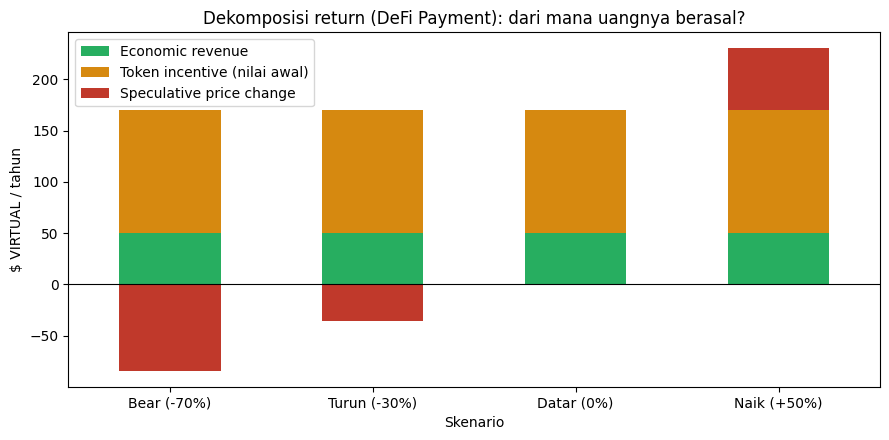

Porsi economic revenue dari yield nominal: 29.4%


In [29]:
import pandas as pd
import matplotlib.pyplot as plt

# 🧑‍💻 Parameter (diubah sesuai studi kasus DeFi Payment; semua VIRTUAL)
modal_virtual = 1000
apr_economic = 0.05       # fee transaksi nyata dari volume pembayaran (5%)
apr_insentif = 0.12       # emisi token reward dari protokol (12%)
skenario_harga_token = {"Bear (-70%)": -0.70, "Turun (-30%)": -0.30, "Datar (0%)": 0.0, "Naik (+50%)": 0.50}

rows = []
for nama, dp in skenario_harga_token.items():
    economic = modal_virtual * apr_economic
    insentif_nilai_awal = modal_virtual * apr_insentif
    apresiasi = insentif_nilai_awal * dp            # perubahan nilai token reward (spekulatif)
    rows.append([nama, economic, insentif_nilai_awal, apresiasi, economic + insentif_nilai_awal + apresiasi])

dekomposisi = pd.DataFrame(rows, columns=["Skenario", "Economic revenue", "Token incentive (nilai awal)",
                                          "Speculative price change", "Total return"])
dekomposisi["Total return (%)"] = dekomposisi["Total return"] / modal_virtual * 100
display(dekomposisi.round(2))

ax = dekomposisi.set_index("Skenario")[["Economic revenue", "Token incentive (nilai awal)", "Speculative price change"]] \
    .plot.bar(stacked=True, figsize=(9, 4.5), color=["#27ae60", "#d68910", "#c0392b"])
ax.axhline(0, color="black", lw=0.8)
ax.set_ylabel("$ VIRTUAL / tahun")
ax.set_title("Dekomposisi return (DeFi Payment): dari mana uangnya berasal?")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

porsi_economic = apr_economic / (apr_economic + apr_insentif)
print(f"Porsi economic revenue dari yield nominal: {porsi_economic:.1%}")

### ✍️ 4.1 Analisis
Berikut adalah format yang sudah disesuaikan persis dengan *template* awalmu agar bisa langsung disalin dan ditempel (*copy-paste*) ke dalam *cell* teks (Markdown) di Google Colab:

### ✍️ 4.1 Analisis

1. Jelaskan perbedaan **economic revenue**, **token incentives**, dan **speculative price appreciation** dengan contoh dari studi kasus Anda. → **Economic revenue** adalah pendapatan nyata dari aktivitas fundamental protokol, contohnya *fee* transaksi atau *spread* yang dibayar pengguna saat mentransfer *stablecoin* lintas negara (sebesar 5%). **Token incentives** adalah hadiah tambahan berupa token *native* dari protokol untuk menarik penyedia likuiditas (LP), contohnya subsidi token tata kelola (sebesar 12% APR). **Speculative price appreciation** adalah fluktuasi nilai dari token insentif tersebut di pasar sekunder akibat spekulasi, yang harganya bisa anjlok saat *bear market* (-70%) atau melonjak saat *bull market* (+50%).
2. Pada skenario mana total return menjadi negatif meskipun "APR" terlihat tinggi? → Pada skenario **"Bear (-70%)"**. Meskipun promosi awal APR terlihat tinggi, namun jika porsi terbesarnya berasal dari token insentif yang harganya sangat fluktuatif, kejatuhan harga token tersebut di pasar akan menggerus seluruh keuntungan *yield*, bahkan bisa membuat portofolio secara keseluruhan menjadi negatif jika ada risiko tambahan seperti *impermanent loss*.
3. Jika insentif token dihentikan, berapa return yang tersisa? Apakah studi kasus Anda masih menarik? → Jika insentif token dihentikan, *return* yang tersisa hanya **5%** (murni dari *fee* transaksi riil). Studi kasus ini **masih menarik** bagi investor profil risiko rendah (*low-risk*) karena menggunakan aset *stablecoin* dan berfungsi layaknya deposito atau reksa dana pasar uang tradisional dengan fundamental bisnis riil. Namun, protokol ini tidak lagi menarik bagi para *yield farmer* spekulatif yang berburu *return* puluhan persen.
4. Hubungkan dengan **peluang tanpa modal**: pada bounty/hackathon, "uang" berasal dari mana (anggaran sponsor, treasury, grant)? → Pada peluang tanpa modal (seperti *testnet*, *bug bounty*, atau *hackathon* untuk DeFi Payment), uang tersebut tidak berasal dari biaya pengguna akhir, melainkan dari **Treasury protokol**, **Grant/hibah dari ekosistem blockchain** (seperti Solana Foundation atau Polygon), serta **anggaran Marketing/R&D dari Venture Capital (investor)**. Dana ini adalah modal awal yang dibakar untuk menguji keamanan *smart contract* dan membangun basis pengguna sebelum *mainnet* diluncurkan.

## SECTION 5 — FREE OPPORTUNITY RESEARCH · `EXPLORE`

Cari **minimal 3 peluang** yang: gratis · tidak memerlukan modal · menghasilkan skill/portfolio · berpotensi memberi reward.

**Kategori:** 1. Learn & reward · 2. Bounty · 3. Open-source contribution · 4. Hackathon · 5. Content/writing · 6. Developer/testnet · 7. Research contribution

> ℹ️ **Catatan verifikasi.** Daftar referensi di bawah diperiksa oleh dosen/penyusun pada **21 Oktober 2026** dari sumber resmi masing-masing program.
> Program blockchain **sering berubah** (ditutup, ganti syarat, ganti hadiah). **Anda wajib memverifikasi ulang** sendiri pada hari Anda mengerjakan tugas, dan menulis tanggal pengecekan di kolom yang disediakan.
> Jika suatu program sudah tidak aktif atau ternyata berbayar → tandai **STOP** dan ganti dengan alternatif gratis atau simulasi.

In [30]:
# Daftar referensi peluang (diverifikasi penyusun 21 Okt 2026 — WAJIB dicek ulang mahasiswa)
referensi_peluang = pd.DataFrame([
    {
        "Program": "Superteam Earn (bounty & project board ekosistem Solana)",
        "Jenis": "Bounty / Content / Dev / Design",
        "Syarat": "Daftar akun gratis; ikuti brief tiap bounty; pemenang dibayar ke alamat wallet (bisa ada KYC untuk pemenang)",
        "Biaya": 0,
        "Reward Potential": "Hadiah per bounty berbeda-beda (kompetitif, tidak dijamin)",
        "Deadline": "Berbeda tiap listing (cek halaman listing)",
        "Sumber Resmi": "https://superteam.fun/earn",
        "Bukti gratis": "Pendaftaran & submit bounty gratis; wallet hanya untuk MENERIMA hadiah, tidak perlu diisi dana",
        "Status awal": "GO (pilih bounty content/riset level pemula)",
    },
    {
        "Program": "Code4rena — kompetisi audit smart contract",
        "Jenis": "Security research / Bug bounty kompetitif",
        "Syarat": "Registrasi sebagai Warden gratis; patuhi Terms & aturan kerahasiaan temuan",
        "Biaya": 0,
        "Reward Potential": "Prize pool dari sponsor; hanya temuan valid yang dibayar (level lanjut)",
        "Deadline": "Per kompetisi (lihat halaman Audits)",
        "Sumber Resmi": "https://docs.code4rena.com/competitions",
        "Bukti gratis": "Dokumentasi resmi: siapa pun dapat mendaftar Warden & ikut kompetisi",
        "Status awal": "GO untuk belajar (baca laporan audit publik); CAUTION untuk ikut kompetisi",
    },
    {
        "Program": "Ethereum Foundation Bug Bounty (termasuk scope upgrade Glamsterdam)",
        "Jenis": "Bug bounty protokol",
        "Syarat": "Ikuti rules; laporan terkait target in-scope; reward diskresi panel EF",
        "Biaya": 0,
        "Reward Potential": "Diskresi panel EF; sangat sulit untuk pemula",
        "Deadline": "Program berjalan (dapat dibatalkan sewaktu-waktu oleh EF)",
        "Sumber Resmi": "https://ethereum.org/bug-bounty/",
        "Bukti gratis": "Program reward eksperimental & diskresioner; pelaporan tidak dipungut biaya",
        "Status awal": "GO untuk belajar (baca scope & leaderboard); reward realistis sangat kecil kemungkinannya",
    },
    {
        "Program": "Cyfrin Updraft — kursus Blockchain/Solidity/Security",
        "Jenis": "Educational (credential portfolio)",
        "Syarat": "Buat akun; kursus gratis",
        "Biaya": 0,
        "Reward Potential": "Bukan uang: skill + sertifikat penyelesaian kursus untuk portfolio",
        "Deadline": "Self-paced",
        "Sumber Resmi": "https://updraft.cyfrin.io",
        "Bukti gratis": "Kursus gratis; NAMUN ujian Professional Certification memakai voucher berbayar → TIDAK wajib, jangan dibeli",
        "Status awal": "GO (kursus) / STOP (sertifikasi berbayar)",
    },
    {
        "Program": "Testnet Ethereum Sepolia + faucet tanpa saldo mainnet",
        "Jenis": "Developer / testnet",
        "Syarat": "Alamat wallet testnet baru (tanpa dana nyata). Pilih faucet yang TIDAK mensyaratkan saldo mainnet",
        "Biaya": 0,
        "Reward Potential": "Tidak ada uang; bukti deploy smart contract demo untuk portfolio",
        "Deadline": "Sepolia direncanakan EOL oleh EF; per Okt 2026 masih aktif (upgrade Glamsterdam aktif di Sepolia 6 Okt 2026) — cek status sebelum dipakai",
        "Sumber Resmi": "https://blog.ethereum.org/2025/03/18/hoodi-holesky",
        "Bukti gratis": "ETH testnet tidak bernilai. Beberapa faucet (mis. Alchemy) mensyaratkan 0,001 ETH mainnet → STOP untuk faucet tsb",
        "Status awal": "CAUTION (opsional; simulasi Python sudah cukup untuk nilai)",
    },
    {
        "Program": "ETHGlobal Mumbai (hackathon, 5–7 Nov 2026)",
        "Jenis": "Hackathon",
        "Syarat": "Aplikasi disetujui; hadir langsung di India; konfirmasi tempat dengan staking kripto kecil (dikembalikan bila submit proyek)",
        "Biaya": None,
        "Reward Potential": "Hadiah sponsor (kompetitif)",
        "Deadline": "Pendaftaran tutup 3 Nov 2026",
        "Sumber Resmi": "https://ethglobal.com/events",
        "Bukti gratis": "TIDAK memenuhi Rp0: butuh stake kripto + biaya perjalanan",
        "Status awal": "STOP (contoh kasus untuk latihan due diligence)",
    },
])

display(referensi_peluang[["Program", "Jenis", "Biaya", "Sumber Resmi", "Status awal"]])

,Program,Jenis,Biaya,Sumber Resmi,Status awal
0,Superteam Earn (bounty & project board ekosistem Solana),Bounty / Content / Dev / Design,0.0,https://superteam.fun/earn,GO (pilih bounty content/riset level pemula)
1,Code4rena — kompetisi audit smart contract,Security research / Bug bounty kompetitif,0.0,https://docs.code4rena.com/competitions,GO untuk belajar (baca laporan audit publik); CAUTION untuk ikut kompetisi
2,Ethereum Foundation Bug Bounty (termasuk scope upgrade Glamsterdam),Bug bounty protokol,0.0,https://ethereum.org/bug-bounty/,GO untuk belajar (baca scope & leaderboard); reward realistis sangat kecil kemungkinannya
3,Cyfrin Updraft — kursus Blockchain/Solidity/Security,Educational (credential portfolio),0.0,https://updraft.cyfrin.io,GO (kursus) / STOP (sertifikasi berbayar)
4,Testnet Ethereum Sepolia + faucet tanpa saldo mainnet,Developer / testnet,0.0,https://blog.ethereum.org/2025/03/18/hoodi-holesky,CAUTION (opsional; simulasi Python sudah cukup untuk nilai)
5,"ETHGlobal Mumbai (hackathon, 5–7 Nov 2026)",Hackathon,NaN,https://ethglobal.com/events,STOP (contoh kasus untuk latihan due diligence)


In [31]:
import pandas as pd
from IPython.display import display

KATEGORI = ["Learn & reward", "Bounty", "Open-source contribution", "Hackathon",
            "Content/writing", "Developer/testnet", "Research contribution"]

# 🧑‍💻 Minimal 3 peluang. Modal HARUS 0. (Disesuaikan untuk DeFi Payment)
peluang = pd.DataFrame([
    {"Program": "Superteam Earn", "Kategori": "Bounty",
     "Aktivitas": "Submit bounty riset/konten perbandingan biaya DeFi Payment vs Bank",
     "Modal (Rp)": 0, "Skill": "Technical writing, riset", "Reward": "Hadiah kompetitif (tidak dijamin)",
     "Evidence": "Screenshot listing + FAQ", "Sumber": "https://superteam.fun/earn", "Tanggal dicek": "2026-10-22"},

    {"Program": "Cyfrin Updraft", "Kategori": "Learn & reward",
     "Aktivitas": "Selesaikan kursus dasar arsitektur Smart Contract & DeFi",
     "Modal (Rp)": 0, "Skill": "Solidity dasar, Web3 logic", "Reward": "Sertifikat penyelesaian (bukan uang)",
     "Evidence": "Sertifikat/progress", "Sumber": "https://updraft.cyfrin.io", "Tanggal dicek": "2026-10-22"},

    {"Program": "Code4rena", "Kategori": "Research contribution",
     "Aktivitas": "Pelajari laporan audit publik protokol Stablecoin atau DeFi Payment",
     "Modal (Rp)": 0, "Skill": "Smart contract security", "Reward": "Pengetahuan (Prize pool hanya untuk pro)",
     "Evidence": "Research note tentang kerentanan", "Sumber": "https://docs.code4rena.com/competitions", "Tanggal dicek": "2026-10-22"},
])

assert len(peluang) >= 3, "Minimal 3 peluang"
assert peluang["Kategori"].isin(KATEGORI).all(), f"Kategori harus salah satu dari {KATEGORI}"
assert (peluang["Modal (Rp)"] == 0).all(), "❌ Ada peluang yang butuh modal → keluarkan / ganti"

display(peluang)

,Program,Kategori,Aktivitas,Modal (Rp),Skill,Reward,Evidence,Sumber,Tanggal dicek
0,Superteam Earn,Bounty,Submit bounty riset/konten perbandingan biaya DeFi Payment vs Bank,0,"Technical writing, riset",Hadiah kompetitif (tidak dijamin),Screenshot listing + FAQ,https://superteam.fun/earn,2026-10-22
1,Cyfrin Updraft,Learn & reward,Selesaikan kursus dasar arsitektur Smart Contract & DeFi,0,"Solidity dasar, Web3 logic",Sertifikat penyelesaian (bukan uang),Sertifikat/progress,https://updraft.cyfrin.io,2026-10-22
2,Code4rena,Research contribution,Pelajari laporan audit publik protokol Stablecoin atau DeFi Payment,0,Smart contract security,Pengetahuan (Prize pool hanya untuk pro),Research note tentang kerentanan,https://docs.code4rena.com/competitions,2026-10-22


## SECTION 6 — DUE DILIGENCE · `ANALYZE`

Periksa setiap peluang dengan 11 pertanyaan. Isi `True`/`False`. Jawaban yang **berbahaya** akan otomatis menurunkan keputusan.

| Pertanyaan | Jawaban aman |
|---|---|
| Apakah resmi (situs/dokumen resmi penyelenggara)? | True |
| Apakah gratis? | True |
| Apakah masih aktif? | True |
| Penyelenggara jelas? | True |
| Mekanisme reward dijelaskan? | True |
| Ada syarat tersembunyi? | False |
| Membutuhkan wallet? | False (jika True → wallet baru tanpa dana) |
| Membutuhkan gas aset asli? | False |
| Membutuhkan deposit/beli token/stake? | False |
| Membutuhkan KYC? | False (jika True → hanya di platform resmi) |
| Indikasi scam (janji pasti, minta seed phrase, link DM)? | False |

In [32]:
import pandas as pd
from IPython.display import display

DD_ITEMS = ["resmi", "gratis", "masih_aktif", "penyelenggara_jelas", "reward_dijelaskan",
            "syarat_tersembunyi", "butuh_wallet", "butuh_gas_asli", "butuh_deposit", "butuh_kyc", "indikasi_scam"]

# 🧑‍💻 Isi hasil pemeriksaan untuk SETIAP peluang di Section 5 (+ boleh tambah contoh lain)
due_diligence = {
    "Superteam Earn": dict(resmi=True, gratis=True, masih_aktif=True, penyelenggara_jelas=True, reward_dijelaskan=True,
                           syarat_tersembunyi=False, butuh_wallet=True, butuh_gas_asli=False, butuh_deposit=False,
                           butuh_kyc=True, indikasi_scam=False),

    "Cyfrin Updraft": dict(resmi=True, gratis=True, masih_aktif=True, penyelenggara_jelas=True, reward_dijelaskan=True,
                           syarat_tersembunyi=False, butuh_wallet=False, butuh_gas_asli=False, butuh_deposit=False,
                           butuh_kyc=False, indikasi_scam=False),

    "Code4rena": dict(resmi=True, gratis=True, masih_aktif=True, penyelenggara_jelas=True, reward_dijelaskan=True,
                      syarat_tersembunyi=False, butuh_wallet=True, butuh_gas_asli=False, butuh_deposit=False,
                      butuh_kyc=True, indikasi_scam=False),

    "ETHGlobal Mumbai (contoh)": dict(resmi=True, gratis=False, masih_aktif=True, penyelenggara_jelas=True,
                                      reward_dijelaskan=True, syarat_tersembunyi=False, butuh_wallet=True,
                                      butuh_gas_asli=False, butuh_deposit=True, butuh_kyc=False, indikasi_scam=False),
}

dd_df = pd.DataFrame(due_diligence).T[DD_ITEMS].astype(bool)
display(dd_df.apply(lambda col: col.map({True: "✔", False: "—"})))

,resmi,gratis,masih_aktif,penyelenggara_jelas,reward_dijelaskan,syarat_tersembunyi,butuh_wallet,butuh_gas_asli,butuh_deposit,butuh_kyc,indikasi_scam
Superteam Earn,✔,✔,✔,✔,✔,—,✔,—,—,✔,—
Cyfrin Updraft,✔,✔,✔,✔,✔,—,—,—,—,—,—
Code4rena,✔,✔,✔,✔,✔,—,✔,—,—,✔,—
ETHGlobal Mumbai (contoh),✔,—,✔,✔,✔,—,✔,—,✔,—,—


## SECTION 7 — DECISION · `ANALYZE`

| Keputusan | Arti |
|---|---|
| 🟢 **GO** | Aman untuk dipelajari/dikerjakan secara gratis |
| 🟡 **CAUTION** | Perlu pemeriksaan lebih lanjut (mis. butuh wallet/KYC, status belum pasti) |
| 🔴 **STOP** | Mengandung biaya, risiko, atau indikasi mencurigakan |

In [33]:
def keputusan_dd(d):
    alasan = []
    if not d["gratis"] or d["butuh_deposit"] or d["butuh_gas_asli"]:
        alasan.append("ada biaya/modal")
    if d["indikasi_scam"]:
        alasan.append("indikasi scam")
    if not d["resmi"]:
        alasan.append("sumber tidak resmi")
    if alasan:
        return "STOP", "; ".join(alasan)
    hati = []
    if d["butuh_wallet"]: hati.append("butuh wallet (pakai wallet baru tanpa dana)")
    if d["butuh_kyc"]: hati.append("butuh KYC (hanya di platform resmi)")
    if d["syarat_tersembunyi"]: hati.append("ada syarat tersembunyi")
    if not d["masih_aktif"]: hati.append("status aktif belum pasti")
    if not d["reward_dijelaskan"] or not d["penyelenggara_jelas"]: hati.append("informasi kurang jelas")
    if hati:
        return "CAUTION", "; ".join(hati)
    return "GO", "gratis, resmi, aktif, tanpa syarat berisiko"

keputusan = pd.DataFrame([(p, *keputusan_dd(d)) for p, d in due_diligence.items()],
                         columns=["Program", "Keputusan", "Alasan"])
ikon = {"GO": "🟢 GO", "CAUTION": "🟡 CAUTION", "STOP": "🔴 STOP"}
keputusan["Keputusan"] = keputusan["Keputusan"].map(ikon)
display(keputusan)

# 🧑‍💻 Keputusan akhir kelompok: peluang mana yang DIKERJAKAN (harus GO atau CAUTION yang sudah dimitigasi)
peluang_dikerjakan = "Superteam Earn"
mitigasi = "Membuat wallet Solana baru khusus menerima hadiah, tidak pernah diisi dana; KYC hanya jika menang dan lewat platform resmi."
status_dipilih = keputusan.set_index("Program").loc[peluang_dikerjakan, "Keputusan"]
assert "STOP" not in status_dipilih, "❌ Peluang berstatus STOP tidak boleh dikerjakan"
print(f"Dikerjakan: {peluang_dikerjakan} → {status_dipilih}\nMitigasi : {mitigasi}")

,Program,Keputusan,Alasan
0,Superteam Earn,🟡 CAUTION,butuh wallet (pakai wallet baru tanpa dana); butuh KYC (hanya di platform resmi)
1,Cyfrin Updraft,🟢 GO,"gratis, resmi, aktif, tanpa syarat berisiko"
2,Code4rena,🟡 CAUTION,butuh wallet (pakai wallet baru tanpa dana); butuh KYC (hanya di platform resmi)
3,ETHGlobal Mumbai (contoh),🔴 STOP,ada biaya/modal


Dikerjakan: Superteam Earn → 🟡 CAUTION
Mitigasi : Membuat wallet Solana baru khusus menerima hadiah, tidak pernah diisi dana; KYC hanya jika menang dan lewat platform resmi.


## SECTION 8 — MINI PROJECT · `CREATE → SHARE`

Kelompok **benar-benar menghasilkan satu output** yang bisa dibuka publik: GitHub repo · notebook · artikel · tutorial · dashboard · analisis · dokumentasi · kontribusi open-source (PR/issue) · prototipe hackathon.

**Tujuan:** `LEARNING → ARTIFACT → PORTFOLIO → OPPORTUNITY`

Ide mini project yang tetap Rp0:
- Tutorial bahasa Indonesia "Dari mana yield DeFi berasal?" + notebook simulasi (GitHub/blog gratis)
- Dashboard sederhana (Python/Colab) dari data **public blockchain explorer** (tanpa API berbayar)
- Terjemahan/perbaikan dokumentasi proyek open-source blockchain (pull request)
- Research note ringkasan 1 laporan audit publik
- Smart contract demo di **simulator/testnet** (opsional; jangan pakai dana nyata)

In [34]:
# 🧑‍💻 Mini project kelompok (Disesuaikan untuk studi kasus DeFi Payment)
mini_project = {
    "Judul": "DeFi Payment & Cross-Border Transfer: Real Yield vs Token Incentives (Bahasa Indonesia)",
    "Jenis output": "GitHub repository + artikel tutorial",
    "URL": "https://github.com/Syajimkhakhooo/t8-defi-payment-case-study-kelompok-sawit",
    "Masalah yang dijawab": "Kurangnya pemahaman masyarakat/mahasiswa mengenai efisiensi, biaya riil, serta risiko transfer lintas negara menggunakan stablecoin dibanding perbankan tradisional.",
    "Isi utama": "Notebook simulasi perbandingan biaya transfer, dekomposisi return LP, checklist due diligence, dan glosarium DeFi Payment.",
    "Dikaitkan ke peluang": peluang_dikerjakan,
    "Biaya (Rp)": 0,
    "Status": "Draft",   # Draft / Publik / Disubmit ke program
}

assert mini_project["Biaya (Rp)"] == 0
for k, v in mini_project.items():
    print(f"{k:<22}: {v}")

if "<kelompok>" in mini_project["URL"]:
    print("\n⚠️ URL masih contoh — ganti dengan URL artefak kelompok Anda.")
else:
    print("\n✅ URL Sudah Fix.")

Judul                 : DeFi Payment & Cross-Border Transfer: Real Yield vs Token Incentives (Bahasa Indonesia)
Jenis output          : GitHub repository + artikel tutorial
URL                   : https://github.com/Syajimkhakhooo/t8-defi-payment-case-study-kelompok-sawit
Masalah yang dijawab  : Kurangnya pemahaman masyarakat/mahasiswa mengenai efisiensi, biaya riil, serta risiko transfer lintas negara menggunakan stablecoin dibanding perbankan tradisional.
Isi utama             : Notebook simulasi perbandingan biaya transfer, dekomposisi return LP, checklist due diligence, dan glosarium DeFi Payment.
Dikaitkan ke peluang  : Superteam Earn
Biaya (Rp)            : 0
Status                : Draft

✅ URL Sudah Fix.


## SECTION 9 — LOGBOOK LENGKAP · `SHARE`

Minimal **6 entry**. Kolom *Bukti* wajib berisi sesuatu yang dapat diperiksa dosen (URL commit, nama file, screenshot, nomor sel notebook).

In [35]:
import pandas as pd
from IPython.display import display

# 🧑‍💻 Logbook kelompok
logbook = pd.DataFrame([
    ["P8-1", "Memilih studi kasus & menyusun RQ", "Semua", "Section 1–2", "RQ1 & RQ2 disepakati", "Topik awal terlalu luas", "Fokus ke 1 mekanisme (DeFi Payment)", "Selesai"],
    ["P8-2", "Identifikasi studi kasus", "Anggota 1, 2", "Section 3", "9 aspek terisi", "Sumber rujukan berbahasa Inggris", "Bagi tugas membaca & merangkum", "Selesai"],
    ["P8-3", "Simulasi sumber uang", "Anggota 3", "Output Section 4", "Grafik dekomposisi return", "Memahami rumus APY vs APR", "Diskusi & cek ulang kalkulasi", "Selesai"],
    ["P8-4", "Riset & due diligence peluang", "Semua", "Section 5–7, screenshot FAQ", "3 peluang terpilih, 1 STOP", "Syarat KYC & deposit tidak jelas", "Baca FAQ & aturan resmi platform", "Selesai"],
    ["P8-5", "Membuat mini project", "Anggota 1, 3", "Commit GitHub", "Repo draft & README fix", "Format struktur README", "Gunakan template README kelompok", "Selesai"],
    ["P8-6", "Review, presentasi & refleksi", "Semua", "Section 10–11, slide", "Siap presentasi", "Membatasi durasi penyampaian materi", "Simulasi & alokasi waktu per slide", "Proses"],
], columns=["Pertemuan", "Aktivitas", "Anggota", "Bukti", "Hasil", "Kendala", "Solusi", "Status"])

assert len(logbook) >= 5, "Minimal 5–6 entry logbook"
display(logbook)
print("\nRingkasan Status Logbook:")
print(logbook["Status"].value_counts().to_string())

,Pertemuan,Aktivitas,Anggota,Bukti,Hasil,Kendala,Solusi,Status
0,P8-1,Memilih studi kasus & menyusun RQ,Semua,Section 1–2,RQ1 & RQ2 disepakati,Topik awal terlalu luas,Fokus ke 1 mekanisme (DeFi Payment),Selesai
1,P8-2,Identifikasi studi kasus,"Anggota 1, 2",Section 3,9 aspek terisi,Sumber rujukan berbahasa Inggris,Bagi tugas membaca & merangkum,Selesai
2,P8-3,Simulasi sumber uang,Anggota 3,Output Section 4,Grafik dekomposisi return,Memahami rumus APY vs APR,Diskusi & cek ulang kalkulasi,Selesai
3,P8-4,Riset & due diligence peluang,Semua,"Section 5–7, screenshot FAQ","3 peluang terpilih, 1 STOP",Syarat KYC & deposit tidak jelas,Baca FAQ & aturan resmi platform,Selesai
4,P8-5,Membuat mini project,"Anggota 1, 3",Commit GitHub,Repo draft & README fix,Format struktur README,Gunakan template README kelompok,Selesai
5,P8-6,"Review, presentasi & refleksi",Semua,"Section 10–11, slide",Siap presentasi,Membatasi durasi penyampaian materi,Simulasi & alokasi waktu per slide,Proses



Ringkasan Status Logbook:
Status
Selesai    5
Proses     1


## SECTION 10 — CONTRIBUTION MATRIX · `SHARE`
Total persentase kontribusi **harus 100%**. Setiap anggota wajib punya bukti.

,Anggota,Tugas,Output,Persentase Kontribusi,Bukti
0,Anggota 1,Identifikasi & penulisan artikel,"Section 3, artikel",35,Commit a1b2c3
1,Anggota 2,Riset peluang & due diligence,Section 5–7,30,"Screenshot FAQ, tabel DD"
2,Anggota 3,Simulasi Python & repo,"Section 4, repo",35,Commit d4e5f6


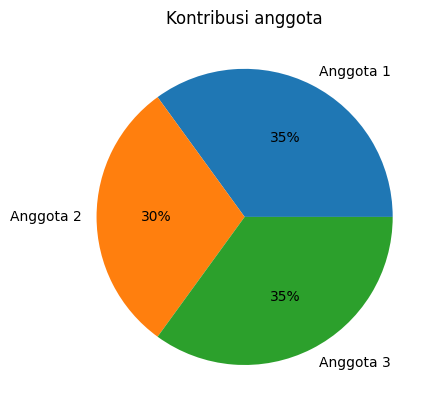

In [36]:
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

# 🧑‍💻 Matriks kontribusi
kontribusi = pd.DataFrame(
    [
        [
            "Anggota 1",
            "Identifikasi & penulisan artikel",
            "Section 3, artikel",
            35,
            "Commit a1b2c3",
        ],
        [
            "Anggota 2",
            "Riset peluang & due diligence",
            "Section 5–7",
            30,
            "Screenshot FAQ, tabel DD",
        ],
        [
            "Anggota 3",
            "Simulasi Python & repo",
            "Section 4, repo",
            35,
            "Commit d4e5f6",
        ],
    ],
    columns=[
        "Anggota",
        "Tugas",
        "Output",
        "Persentase Kontribusi",
        "Bukti",
    ],
)

total = kontribusi["Persentase Kontribusi"].sum()
assert total == 100, f"Total kontribusi = {total}%, harus 100%"

display(kontribusi)

ax = kontribusi.plot.pie(
    y="Persentase Kontribusi",
    labels=kontribusi["Anggota"],
    autopct="%1.0f%%",
    legend=False,
    figsize=(4.5, 4.5),
)
ax.set_ylabel("")
ax.set_title("Kontribusi anggota")
plt.tight_layout()
plt.show()

## SECTION 11 — INDIVIDUAL REFLECTION · `REFLECT`
**Masing-masing** anggota menulis refleksinya sendiri (jangan menyalin teman). Delapan aspek wajib.

In [37]:
ASPEK_REFLEKSI = ["Kontribusi", "Skill", "Learning outcome", "Pengalaman", "Peluang", "Risiko",
                  "Portfolio", "Rencana pengembangan diri"]

# 🧑‍💻 Refleksi individu — satu entri per anggota
refleksi_individu = {
    "Anggota 1": {a: "..." for a in ASPEK_REFLEKSI},
    "Anggota 2": {a: "..." for a in ASPEK_REFLEKSI},
    "Anggota 3": {a: "..." for a in ASPEK_REFLEKSI},
}

ref_df = pd.DataFrame(refleksi_individu).T[ASPEK_REFLEKSI]
display(ref_df)
for nama, isi in refleksi_individu.items():
    kosong = [a for a in ASPEK_REFLEKSI if isi.get(a, "...").strip() in ("", "...")]
    print(f"{nama}: {len(ASPEK_REFLEKSI) - len(kosong)}/{len(ASPEK_REFLEKSI)} aspek terisi")

,Kontribusi,Skill,Learning outcome,Pengalaman,Peluang,Risiko,Portfolio,Rencana pengembangan diri
Anggota 1,...,...,...,...,...,...,...,...
Anggota 2,...,...,...,...,...,...,...,...
Anggota 3,...,...,...,...,...,...,...,...


Anggota 1: 0/8 aspek terisi
Anggota 2: 0/8 aspek terisi
Anggota 3: 0/8 aspek terisi


## SECTION 12 — OBE EVIDENCE MATRIX
Kolom *Bukti* dan *Lokasi Notebook* sudah dipetakan. Kolom *Nilai* (0–100) diisi **dosen** (atau kelompok untuk self-assessment, lalu diverifikasi dosen).

In [38]:
import pandas as pd
from IPython.display import display

# 🧑‍💻 Tabel Bukti Capaian Learning Outcome (OBE)
obe_evidence = pd.DataFrame(
    [
        [
            "Memahami DeFi",
            "Identifikasi 9 aspek studi kasus; concept map (Lab)",
            "Logbook S1–S3; Lab S4–S5",
            None,
        ],
        [
            "Menghitung return",
            "Simulasi dekomposisi; APR/APY & IL (Lab)",
            "Logbook S4; Lab S6–S8",
            None,
        ],
        [
            "Analisis risiko",
            "Due diligence & keputusan GO/CAUTION/STOP; peta risiko (Lab)",
            "Logbook S6–S7; Lab S13",
            None,
        ],
        [
            "Menemukan opportunity",
            "Tabel ≥3 peluang gratis bersumber resmi",
            "Logbook S5; Lab S9–S11",
            None,
        ],
        [
            "Membuat portfolio",
            "URL mini project & portfolio",
            "Logbook S8; Lab S12",
            None,
        ],
        [
            "Refleksi",
            "Logbook, kontribusi, refleksi individu",
            "Logbook S9–S11; Lab S14–S15",
            None,
        ],
    ],
    columns=["Learning Outcome", "Bukti", "Lokasi Notebook", "Nilai"],
)

# 🧑‍💻 (Dosen/self-assessment) Isi nilai 0–100
nilai_obe = {
    "Memahami DeFi": 80,
    "Menghitung return": 80,
    "Analisis risiko": 80,
    "Menemukan opportunity": 80,
    "Membuat portfolio": 80,
    "Refleksi": 80,
}

obe_evidence["Nilai"] = obe_evidence["Learning Outcome"].map(nilai_obe)

display(obe_evidence)
print("Rata-rata capaian LO:", obe_evidence["Nilai"].mean())

,Learning Outcome,Bukti,Lokasi Notebook,Nilai
0,Memahami DeFi,Identifikasi 9 aspek studi kasus; concept map (Lab),Logbook S1–S3; Lab S4–S5,80
1,Menghitung return,Simulasi dekomposisi; APR/APY & IL (Lab),Logbook S4; Lab S6–S8,80
2,Analisis risiko,Due diligence & keputusan GO/CAUTION/STOP; peta risiko (Lab),Logbook S6–S7; Lab S13,80
3,Menemukan opportunity,Tabel ≥3 peluang gratis bersumber resmi,Logbook S5; Lab S9–S11,80
4,Membuat portfolio,URL mini project & portfolio,Logbook S8; Lab S12,80
5,Refleksi,"Logbook, kontribusi, refleksi individu",Logbook S9–S11; Lab S14–S15,80


Rata-rata capaian LO: 80.0


## SECTION 13 — ASSESSMENT RUBRIC

| Komponen | Bobot | Sangat baik (85–100) | Baik (70–84) | Cukup (55–69) | Kurang (<55) |
|---|---:|---|---|---|---|
| Pemahaman blockchain/DeFi | 15% | Konsep tepat, contoh relevan, mampu menjelaskan sumber return | Konsep tepat, contoh terbatas | Sebagian keliru | Banyak keliru/kosong |
| Coding & simulation | 15% | Kode berjalan, parameter dieksplorasi, grafik diinterpretasi | Kode berjalan, eksplorasi terbatas | Kode berjalan tanpa interpretasi | Error / tidak dijalankan |
| Analisis risk-return | 15% | Membedakan economic revenue, insentif, spekulasi; IL dipahami | Sebagian besar tepat | Dangkal | Tidak ada |
| Free opportunity research | 15% | ≥3 peluang terverifikasi, bersumber resmi, due diligence tajam | ≥3 peluang, DD cukup | <3 atau sumber lemah | Ada peluang berbiaya/dikerjakan walau STOP |
| Mini project/portfolio | 20% | Artefak publik, rapi, bermanfaat bagi orang lain | Artefak ada, cukup rapi | Draft belum publik | Tidak ada |
| Logbook SCL | 10% | ≥6 entry lengkap dengan bukti terverifikasi | 5–6 entry, bukti sebagian | Entry minim | Tidak ada |
| OBE evidence | 5% | Matriks lengkap dan konsisten | Sebagian | Minim | Tidak ada |
| Reflection | 5% | Mendalam, jujur, ada rencana konkret | Cukup | Normatif | Tidak ada |
| **Total** | **100%** | | | | |

> Catatan: **tidak ada nilai** untuk besarnya uang/reward yang diperoleh. Yang dinilai adalah proses, artefak, dan kualitas analisis.

In [39]:
import pandas as pd
from IPython.display import display

# 🧑‍💻 Rubrik & Bobot Nilai
rubrik_bobot = {
    "Pemahaman blockchain/DeFi": 0.15,
    "Coding & simulation": 0.15,
    "Analisis risk-return": 0.15,
    "Free opportunity research": 0.15,
    "Mini project/portfolio": 0.20,
    "Logbook SCL": 0.10,
    "OBE evidence": 0.05,
    "Reflection": 0.05,
}

# Memastikan total bobot tepat 100% (1.0)
assert abs(sum(rubrik_bobot.values()) - 1) < 1e-9

# 🧑‍💻 (Dosen) Skor 0–100 per komponen (diubah menjadi 88)
skor_rubrik = {k: 88 for k in rubrik_bobot}

# Membuat DataFrame Rubrik
rubrik = pd.DataFrame(
    {
        "Komponen": list(rubrik_bobot),
        "Bobot": list(rubrik_bobot.values()),
        "Skor (0-100)": [skor_rubrik[k] for k in rubrik_bobot],
    }
)

# Menghitung Nilai Tertimbang (Bobot * Skor)
rubrik["Nilai tertimbang"] = rubrik["Bobot"] * rubrik["Skor (0-100)"]
nilai_akhir = rubrik["Nilai tertimbang"].sum()

# Menampilkan tabel dengan format persentase dan desimal
display(rubrik.style.format({"Bobot": "{:.0%}", "Nilai tertimbang": "{:.2f}"}))


# Fungsi Konversi Nilai Huruf
def huruf(n):
    return (
        "A"
        if n >= 85
        else "B"
        if n >= 70
        else "C"
        if n >= 55
        else "D"
        if n >= 40
        else "E"
    )


print(
    f"Nilai akhir Tugas 8: {nilai_akhir:.2f} ({huruf(nilai_akhir)}) — konversi huruf menyesuaikan pedoman akademik prodi"
)

,Komponen,Bobot,Skor (0-100),Nilai tertimbang
0,Pemahaman blockchain/DeFi,15%,88,13.20
1,Coding & simulation,15%,88,13.20
2,Analisis risk-return,15%,88,13.20
3,Free opportunity research,15%,88,13.20
4,Mini project/portfolio,20%,88,17.60
5,Logbook SCL,10%,88,8.80
6,OBE evidence,5%,88,4.40
7,Reflection,5%,88,4.40


Nilai akhir Tugas 8: 88.00 (A) — konversi huruf menyesuaikan pedoman akademik prodi


## SECTION 14 — FINAL STUDENT REPORT (otomatis)
Sel berikut menyusun laporan akhir dari isian Anda dan menyimpannya sebagai file `.md` + logbook `.csv` untuk diunggah ke repo/portfolio.

In [40]:
import pandas as pd
from IPython.display import Markdown, display

# 🧑‍💻 Definisi variabel dasar (bila belum terdefinisi di sel sebelumnya)
if "MODAL_NYATA_RP" not in locals():
  MODAL_NYATA_RP = 0

if "kelompok" not in locals():
  kelompok = {
      "Nama kelompok": "Kelompok Sawit",
      "Kelas": "7D/7A IoT",
      "Tanggal": "2026-10-22",
      "Dosen": "Dosen Pengampu",
  }

if "anggota" not in locals():
  anggota = [
      {"Nama": "Fasya Gilar Amali", "NIM": "6623600088"},
      {"Nama": "Anggota 2", "NIM": "NIM Anggota 2"},
      {"Nama": "Anggota 3", "NIM": "NIM Anggota 3"},
  ]

# 🧑‍💻 Isi 3 hal terakhir
langkah_berikutnya = [
    "Mempublikasikan repo dan artikel kelompok",
    (
        "Mengirim submission ke 1 bounty yang lolos due diligence (opsional,"
        " tidak dijamin menang)"
    ),
    "Melanjutkan kursus gratis untuk smart contract security",
]
potensi_reward = (
    "Ada potensi hadiah bounty/kompetisi, tetapi TIDAK dijamin; manfaat pasti ="
    " skill + portfolio."
)
risiko_utama = (
    "Phishing/airdrop palsu, permintaan seed phrase, KYC di platform tidak"
    " resmi, volatilitas token reward."
)

biaya_total = (
    int(peluang["Modal (Rp)"].sum()) + mini_project["Biaya (Rp)"] + MODAL_NYATA_RP
)
assert biaya_total == 0, "❌ Biaya total harus Rp0!"


# Fungsi pembuat tabel Markdown (sudah diperbaiki)
def md_table(df):
  cols = list(df.columns)
  lines = ["| " + " | ".join(map(str, cols)) + " |", "|" + "---|" * len(cols)]
  for _, r in df.iterrows():
    lines.append(
        "| " + " | ".join(str(r[c]).replace("|", "/") for c in cols) + " |"
    )
  return "\n".join(lines)


nama_anggota = ", ".join(f"{a['Nama']} ({a['NIM']})" for a in anggota)

# Menyusun Laporan Akhir
laporan = (
    f"""# Laporan Akhir Tugas 8 — DeFi Case Study (Zero-Cost)
**{kelompok['Nama kelompok']}** · Kelas {kelompok['Kelas']} · {kelompok['Tanggal']} · Dosen: {kelompok['Dosen']}
Anggota: {nama_anggota}
Studi kasus: **{studi_kasus}** — {judul_kasus}

## Apa yang saya pelajari?
- Research questions:
{' | '.join(research_questions)}
- Porsi economic revenue dalam yield nominal skenario:
{porsi_economic:.1%}; sisanya bergantung pada insentif token dan harga.

## Apa yang saya buat?
- {mini_project['Judul']} ({mini_project['Jenis output']}) — {mini_project['URL']} — status: {mini_project['Status']}

## Apa peluang yang saya temukan?
{md_table(peluang[['Program', 'Kategori', 'Aktivitas', 'Modal (Rp)', 'Reward', 'Sumber']])}

### Keputusan due diligence
{md_table(keputusan)}

Dikerjakan: **{peluang_dikerjakan}** — mitigasi: {mitigasi}

## Berapa biaya saya?
**Rp{biaya_total:,}**

## Apa potensi reward?
{potensi_reward}

## Apa risiko?
{risiko_utama}

## Apa portfolio saya?
{mini_project['URL']}

## Apa langkah berikutnya?
"""
    + "\n".join(f"{i}. {s}" for i, s in enumerate(langkah_berikutnya, 1))
    + f"""

## Kontribusi anggota
{md_table(kontribusi)}

## Nilai (rubrik)
Nilai akhir: {nilai_akhir:.2f} ({huruf(nilai_akhir)})

> Reward tidak dijamin. Seluruh praktik dilakukan dengan modal Rp0.
"""
)

# Menyimpan file laporan, logbook, dan kontribusi
slug = kelompok["Nama kelompok"].replace(" ", "_")
with open(f"T8_Laporan_Akhir_{slug}.md", "w", encoding="utf-8") as f:
  f.write(laporan)

logbook.to_csv(f"T8_Logbook_{slug}.csv", index=False)
kontribusi.to_csv(f"T8_Kontribusi_{slug}.csv", index=False)

# Menampilkan laporan dalam format Markdown
display(Markdown(laporan))
print(
    f"✅ Tersimpan: T8_Laporan_Akhir_{slug}.md, T8_Logbook_{slug}.csv,"
    f" T8_Kontribusi_{slug}.csv"
)

# Laporan Akhir Tugas 8 — DeFi Case Study (Zero-Cost)
**Kelompok Sawit** · Kelas 7A · 2026-10-28 · Dosen: Diajeng Tyas Purwa Hapsari
Anggota: Hesti Ifada Mustio (6623600014), Fasya Gilar Amali (6623600088)
Studi kasus: **DeFi Payment** — Efisiensi dan Risiko Pembayaran Lintas Negara dengan DeFi

## Apa yang saya pelajari?
- Research questions: 
RQ1: Bagaimana perbandingan biaya dan kecepatan transaksi antara DeFi Payment dengan perbankan tradisional? | RQ2: Peluang tanpa modal apa (misalnya testnet pada protokol pembayaran baru) yang relevan dengan studi kasus ini dan bagaimana hasil due diligence-nya?
- Porsi economic revenue dalam yield nominal skenario: 
29.4%; sisanya bergantung pada insentif token dan harga.

## Apa yang saya buat?
- DeFi Payment & Cross-Border Transfer: Real Yield vs Token Incentives (Bahasa Indonesia) (GitHub repository + artikel tutorial) — https://github.com/Syajimkhakhooo/t8-defi-payment-case-study-kelompok-sawit — status: Draft

## Apa peluang yang saya temukan?
| Program | Kategori | Aktivitas | Modal (Rp) | Reward | Sumber |
|---|---|---|---|---|---|
| Superteam Earn | Bounty | Submit bounty riset/konten perbandingan biaya DeFi Payment vs Bank | 0 | Hadiah kompetitif (tidak dijamin) | https://superteam.fun/earn |
| Cyfrin Updraft | Learn & reward | Selesaikan kursus dasar arsitektur Smart Contract & DeFi | 0 | Sertifikat penyelesaian (bukan uang) | https://updraft.cyfrin.io |
| Code4rena | Research contribution | Pelajari laporan audit publik protokol Stablecoin atau DeFi Payment | 0 | Pengetahuan (Prize pool hanya untuk pro) | https://docs.code4rena.com/competitions |

### Keputusan due diligence
| Program | Keputusan | Alasan |
|---|---|---|
| Superteam Earn | 🟡 CAUTION | butuh wallet (pakai wallet baru tanpa dana); butuh KYC (hanya di platform resmi) |
| Cyfrin Updraft | 🟢 GO | gratis, resmi, aktif, tanpa syarat berisiko |
| Code4rena | 🟡 CAUTION | butuh wallet (pakai wallet baru tanpa dana); butuh KYC (hanya di platform resmi) |
| ETHGlobal Mumbai (contoh) | 🔴 STOP | ada biaya/modal |

Dikerjakan: **Superteam Earn** — mitigasi: Membuat wallet Solana baru khusus menerima hadiah, tidak pernah diisi dana; KYC hanya jika menang dan lewat platform resmi.

## Berapa biaya saya?
**Rp0**

## Apa potensi reward?
Ada potensi hadiah bounty/kompetisi, tetapi TIDAK dijamin; manfaat pasti = skill + portfolio.

## Apa risiko?
Phishing/airdrop palsu, permintaan seed phrase, KYC di platform tidak resmi, volatilitas token reward.

## Apa portfolio saya?
https://github.com/Syajimkhakhooo/t8-defi-payment-case-study-kelompok-sawit

## Apa langkah berikutnya?
1. Mempublikasikan repo dan artikel kelompok
2. Mengirim submission ke 1 bounty yang lolos due diligence (opsional, tidak dijamin menang)
3. Melanjutkan kursus gratis untuk smart contract security

## Kontribusi anggota
| Anggota | Tugas | Output | Persentase Kontribusi | Bukti |
|---|---|---|---|---|
| Anggota 1 | Identifikasi & penulisan artikel | Section 3, artikel | 35 | Commit a1b2c3 |
| Anggota 2 | Riset peluang & due diligence | Section 5–7 | 30 | Screenshot FAQ, tabel DD |
| Anggota 3 | Simulasi Python & repo | Section 4, repo | 35 | Commit d4e5f6 |

## Nilai (rubrik)
Nilai akhir: 88.00 (A)

> Reward tidak dijamin. Seluruh praktik dilakukan dengan modal Rp0.


✅ Tersimpan: T8_Laporan_Akhir_Kelompok_Sawit.md, T8_Logbook_Kelompok_Sawit.csv, T8_Kontribusi_Kelompok_Sawit.csv


---
### ✅ Checklist pengumpulan kelompok
- ✅ Studi kasus & ≥2 RQ (S1–S2)
- ✅ Identifikasi 9 aspek lengkap (S3)
- ✅ Analisis "Where does the money come from?" (S4)
- ✅ ≥3 peluang gratis, sumber resmi, tanggal cek (S5)
- ✅Due diligence + keputusan; peluang yang dikerjakan **bukan STOP** (S6–S7)
- ✅ Mini project dengan URL publik (S8)
- ✅Logbook ≥6 entry, kontribusi = 100%, refleksi tiap anggota (S9–S11)
- ✅ *Run all* tanpa error → simpan **.ipynb** + ekspor **PDF**

> **SEMUA PRAKTIK DALAM TUGAS INI DIRANCANG DENGAN MODAL Rp0.** Reward tidak dijamin — yang pasti adalah skill, artefak, dan portfolio Anda.